In [1]:
import tensorflow as tf
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

I0000 00:00:1793044927.913243   14206 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2.21.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input , Conv2D, AveragePooling2D , Flatten , Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator #Data augmentation

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
tf.keras.utils.set_random_seed(42)
IMG_HEIGHT = 32
IMG_WIDTH = 32
BATCH_SIZE = 32

In [ ]:
from pathlib import Path
import kagglehub

DATA_FOLDER = Path(r"C:\Deep learning CampusX\Data")
DATASET_FOLDER = DATA_FOLDER / "dogsvscats"

DATA_FOLDER.mkdir(parents=True, exist_ok=True)

if DATASET_FOLDER.exists() and any(DATASET_FOLDER.iterdir()):
    print("Using the dataset already present in the folder.")
    path = str(DATASET_FOLDER)
else:
    path = kagglehub.dataset_download(
        "salader/dogsvscats",
        output_dir=str(DATASET_FOLDER),
    )

dataset_path = Path(path)

print("Dataset path:", dataset_path)
print("Dataset exists:", dataset_path.exists())

100%|██████████| 1.06G/1.06G [01:31<00:00, 12.4MB/s]

Extracting files...


Dataset path: C:\Deep learning CampusX\Data\dogsvscats
Dataset exists: True


In [ ]:
print("Dataset folder structure:\n")

for folder in sorted(dataset_path.rglob("*")):
    if folder.is_dir():
        print(folder.relative_to(dataset_path))

Dataset folder structure:

.complete
.complete\datasets
.complete\datasets\salader
.complete\datasets\salader\dogsvscats
.complete\datasets\salader\dogsvscats\1
catsvsdogs
catsvsdogs\test
catsvsdogs\test\cats
catsvsdogs\test\dogs
catsvsdogs\train
catsvsdogs\train\cats
catsvsdogs\train\dogs
test
test\cats
test\dogs
train
train\cats
train\dogs


In [ ]:
train_dir = dataset_path / "train"
validation_dir = dataset_path / "test"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

def count_images(folder):
    return sum(
        1
        for file in folder.rglob("*")
        if file.is_file() and file.suffix.lower() in image_extensions
    )

print("Training directory:", train_dir)
print("Validation directory:", validation_dir)

print("\nTraining cats:", count_images(train_dir / "cats"))
print("Training dogs:", count_images(train_dir / "dogs"))
print("Validation cats:", count_images(validation_dir / "cats"))
print("Validation dogs:", count_images(validation_dir / "dogs"))

Training directory: C:\Deep learning CampusX\Data\dogsvscats\train
Validation directory: C:\Deep learning CampusX\Data\dogsvscats\test

Training cats: 10000
Training dogs: 10000
Validation cats: 2500
Validation dogs: 2500


In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    shear_range=0.10,
    zoom_range=0.10,
    horizontal_flip=True,
    fill_mode="nearest",
)

validation_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0
)

print("ImageDataGenerator objects created successfully")

ImageDataGenerator objects created successfully


In [ ]:
train_generator = train_datagen.flow_from_directory(
    directory=str(train_dir),
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    color_mode="rgb",
    classes=["cats", "dogs"],
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42,
)

validation_generator = validation_datagen.flow_from_directory(
    directory=str(validation_dir),
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    color_mode="rgb",
    classes=["cats", "dogs"],
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print("\nClass mapping:", train_generator.class_indices)

Found 20000 images belonging to 2 classes.
Found 5000 images belonging to 2 classes.

Class mapping: {'cats': 0, 'dogs': 1}


In [ ]:
batch_images, batch_labels = next(train_generator)

print("Image batch shape:", batch_images.shape)
print("Label batch shape:", batch_labels.shape)
print("Minimum pixel value:", batch_images.min())
print("Maximum pixel value:", batch_images.max())
print("First 10 labels:", batch_labels[:10])

train_generator.reset()

Image batch shape: (32, 32, 32, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
First 10 labels: [1. 0. 0. 0. 1. 1. 1. 0. 1. 0.]


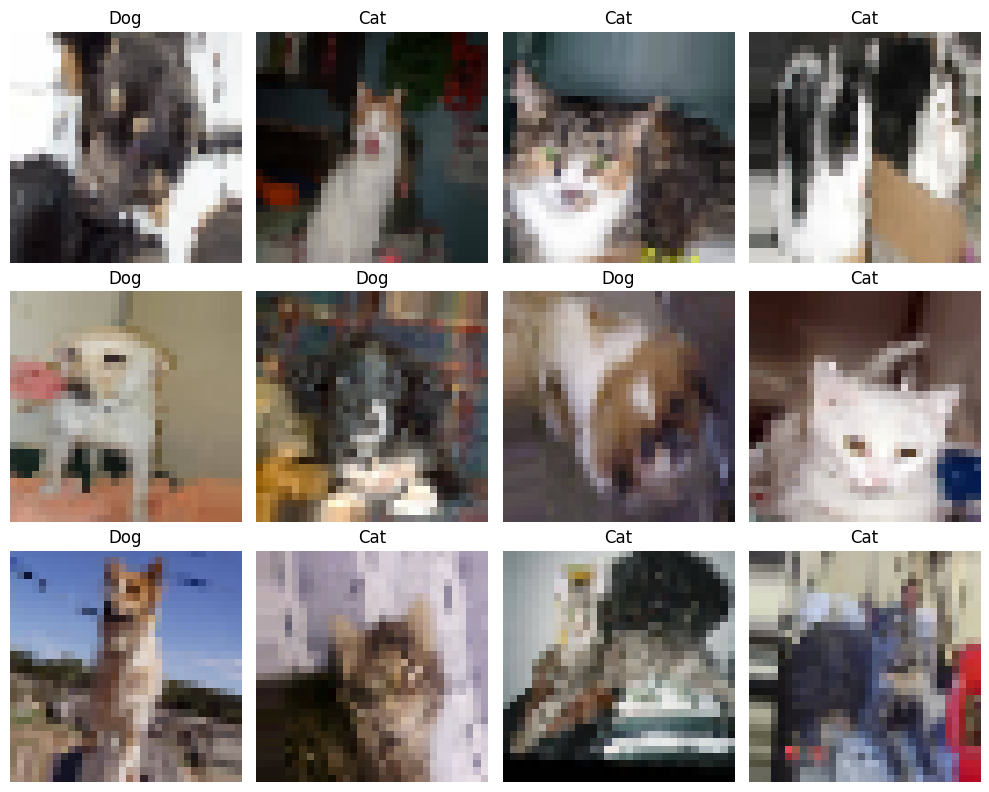

In [ ]:
plt.figure(figsize=(10, 8))

for index in range(12):
    plt.subplot(3, 4, index + 1)

    plt.imshow(batch_images[index])

    label = "Dog" if batch_labels[index] == 1 else "Cat"
    plt.title(label)

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
model = Sequential()
model.add(Input(shape = (IMG_HEIGHT , IMG_WIDTH ,3)))
model.add(Conv2D(filters = 6 , kernel_size = (5,5) , activation = 'tanh' , padding = 'valid'))
model.add(AveragePooling2D(pool_size=(2,2) , strides = 2))

model.add(Conv2D(filters = 16 , kernel_size=(5,5) , activation='tanh' ,padding='valid'))
model.add(AveragePooling2D(pool_size=(2,2) , strides=2))

model.add(Conv2D(filters=120 , kernel_size=(5,5) , activation='tanh' , padding='valid'))
model.add(Flatten())

model.add(Dense(84 , activation = 'tanh'))
model.add(Dense(1 , activation = 'sigmoid'))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_3             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 1, 1, 120)      │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,241 (239.22 KB)

 Trainable params: 61,241 (239.22 KB)

 Non-trainable params: 0 (0.00 B)

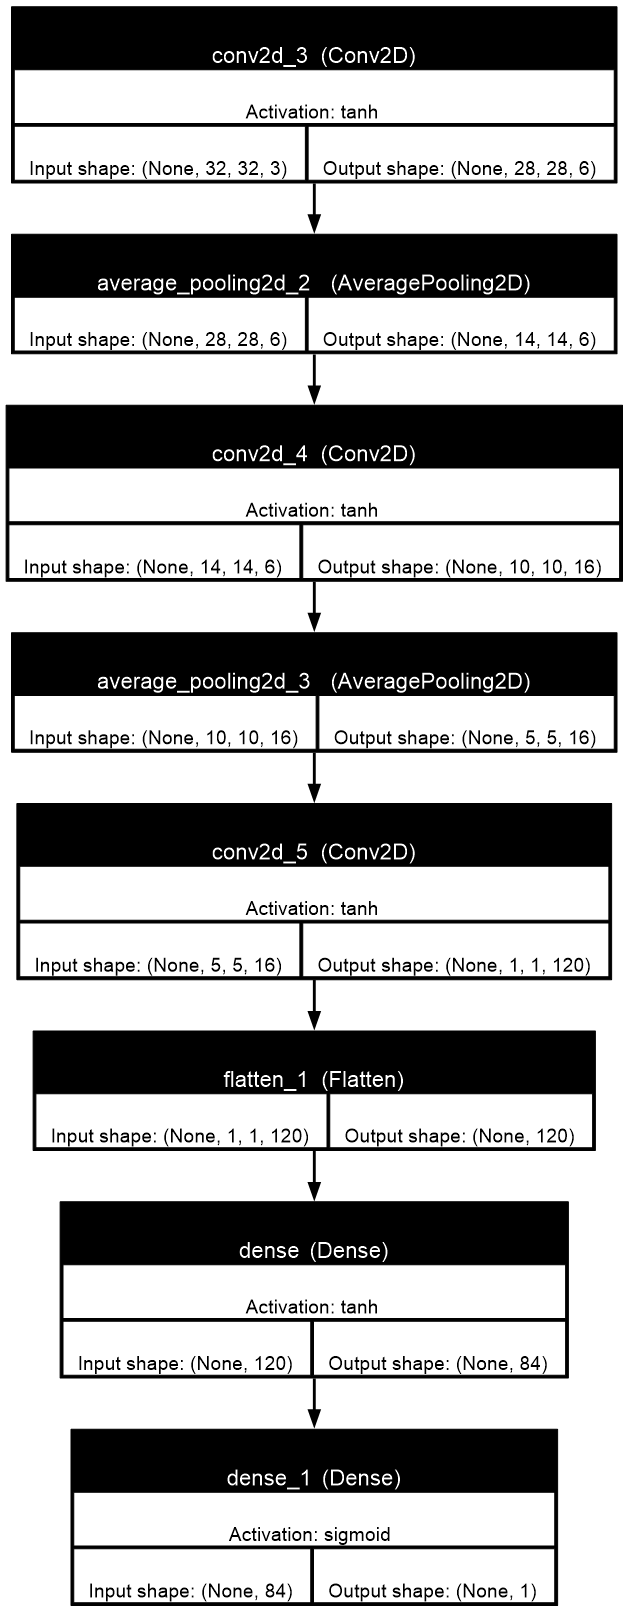

In [ ]:
from tensorflow import keras
keras.utils.plot_model(
    model,
    to_file="lenet5_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    expand_nested=True,
    dpi=100,
)

In [ ]:
model.compile(loss = "binary_crossentropy" , optimizer='adam' , metrics=['accuracy'])


In [ ]:
MODEL_FOLDER = Path(r"C:\Deep learning CampusX\Models")
MODEL_FOLDER.mkdir(parents=True, exist_ok=True)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_FOLDER / "best_lenet5.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1,
    ),
]

print("Callbacks created")

Callbacks created


In [ ]:
train_generator.reset()
validation_generator.reset()

history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=1,
    callbacks=callbacks,
)

625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 495ms/step - accuracy: 0.5657 - loss: 0.6792
Epoch 1: val_loss improved from None to 0.66747, saving model to C:\Deep learning CampusX\Models\best_lenet5.keras

Epoch 1: finished saving model to C:\Deep learning CampusX\Models\best_lenet5.keras
625/625 ━━━━━━━━━━━━━━━━━━━━ 387s 620ms/step - accuracy: 0.5657 - loss: 0.6792 - val_accuracy: 0.5966 - val_loss: 0.6675 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 1.


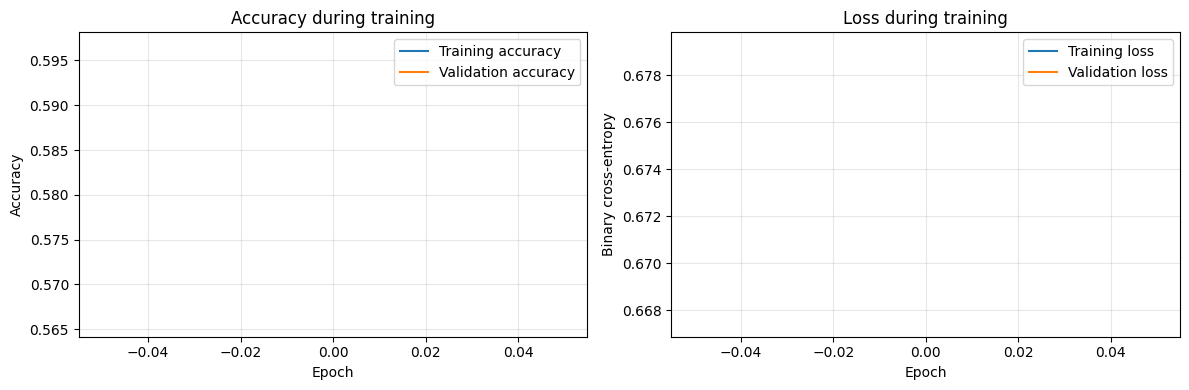

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy during training")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title("Loss during training")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# TENSORFLOW DOESNT HAVE NATIVE GPU SUPPORT ON WINDOWS